# 03 - The NVDA / QQQ trade, explained

**TL;DR** (data through 2026-11-20)
- **The trade:** long \$32k NVDA, short ~\$41k QQQ (h = 1.28, the trailing-year beta). It
  strips out the tech-market part of NVDA's moves and keeps the NVDA-specific part.
- **Risk:** monthly 99% VaR is about \$10.1k on today's EWMA vol (history says
  \$5.7k: vol is elevated right now). Reg T needs \$36.5k of equity, plus a cushion.
- **Backtest 2020-2026, after costs:** about +\$9.4k a year over T-bills (26% of
  equity), Sharpe 0.9, max drawdown \$13.1k (36% of equity). Unhedged NVDA made more
  (Sharpe 1.0) but drew down \$30k. With no rebate on short proceeds, Sharpe drops
  to 0.67.
- **Right now:** the NVDA-specific residual has lost about 32% in 3 months and 46% in 12,
  and November 2026 is the worst month in the backtest.
- **No mean reversion:** the spread behaves like a random walk (ADF p ≈ 0.5, variance
  ratios ≈ 0.9-0.97 and insignificant, half-life interval includes infinity, event
  study t < 1.1). This is a bet on NVDA's own alpha plus carry, not a reversion trade.

In [1]:
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

from nvai import hedge as hg
from nvai.config import FIGURES
from nvai.data import load

warnings.filterwarnings("ignore", category=FutureWarning)   # statsmodels adfuller notice

pd.set_option("display.width", 150, "display.float_format", lambda v: f"{v:,.2f}")
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6",
           "#e34948"]
INK, INK2, GRID, BAD = "#0b0b0b", "#52514e", "#e4e3df", "#e34948"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 1.5, "legend.frameon": False, "font.size": 9,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")
    plt.show()


def usd(x):
    return f"${x:,.0f}"


# The trade
L = 32_000            # $ long NVDA, fixed
TCOST = 0.0010        # 10 bp per side on every dollar traded at a rebalance
ANN, M = 252, 21      # trading days per year / per month

# Data (same loaders as 01 and 02)
ret = load.returns()[["NVDA", "QQQ"]].dropna()
rf = load.risk_free().reindex(ret.index).ffill()
fee = load.borrow_fees(fill_default=True)["QQQ"].reindex(ret.index).ffill()
xn, xq = ret.NVDA - rf, ret.QQQ - rf                        # excess returns

# Hedge ratios, all known at the prior close (no look-ahead)
b252 = hg.rolling_beta(xn, xq, 252)
b63 = hg.rolling_beta(xn, xq, 63)
b_long = (xn.expanding(252).cov(xq) / xq.expanding(252).var())     # full sample to date
h_trail = hg.hold_monthly(b252)                                   # refit monthly
h_shrunk = hg.hold_monthly(0.5 * b252 + 0.5 * b_long)            # 50/50 shrinkage
h_now = b252.iat[-1]
S = h_now * L
print(f"data to {ret.index[-1].date()};  h now = {h_now:.2f};  short QQQ = {usd(S)}")

data to 2026-11-20;  h now = 1.28;  short QQQ = $40,843


## 1. The trade in one picture

**Long \$32k NVDA, short `h` x \$32k of QQQ.** NVDA moves partly because the whole
tech market moves. QQQ captures that part: NVDA has tended to move about `h` times
QQQ's move. Shorting `h` dollars of QQQ per dollar of NVDA cancels the market/tech
part, so **what's left is the NVDA-specific part** (earnings, product news, AI-capex
headlines that hit NVDA more than the rest of tech).

The chart splits NVDA's cumulative excess return into those two pieces, using the
trailing hedge ratio.

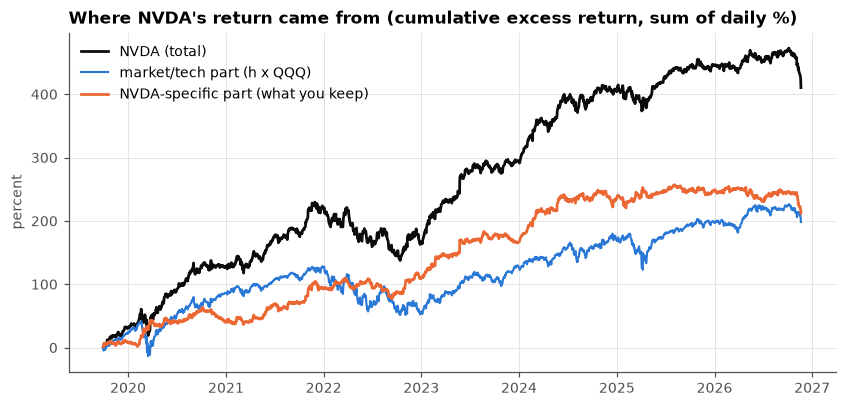

In [2]:
part_mkt = h_trail * xq
part_own = xn - part_mkt
since = part_own.dropna().index[0]
fig, ax = plt.subplots(figsize=(9, 4))
for s, lab, c, lw in [(xn, "NVDA (total)", INK, 1.8), (part_mkt, "market/tech part (h x QQQ)",
                      PALETTE[0], 1.4), (part_own, "NVDA-specific part (what you keep)",
                      PALETTE[1], 1.8)]:
    cum = s[since:].fillna(0).cumsum()
    ax.plot(cum.index, 100 * cum, color=c, lw=lw, label=lab)
ax.set_title("Where NVDA's return came from (cumulative excess return, sum of daily %)")
ax.set_ylabel("percent")
ax.legend(loc="upper left")
save(fig, "03_trade_decomposition")

## 2. Sizing: \$32k long, ~\$41k short, \$10k monthly 99% VaR

- Daily book return per \$1 of NVDA: `u = (r_NVDA - rf) - h * (r_QQQ - rf + fee)`.
- Daily vol comes from EWMA (lambda 0.94) of `u`, which reacts quickly to recent moves.
- Monthly vol = daily vol x sqrt(21). Monthly 99% VaR = 2.326 x monthly vol x L.

The check asks how often the book actually lost more than the forecast. Each day, the
EWMA VaR forecast is set against the realized loss over the next 21 days. A good 99%
VaR is breached on about 1% of days.

In [3]:
u = (xn - h_now * (xq + fee / ANN)).dropna()            # today's h on all past days
sig_d = hg.ewma_vol(u)
sd_now = sig_d.iat[-1]
sizing = pd.Series({
    "long NVDA": L, "short QQQ (h x L)": S,
    "daily vol $ (EWMA)": L * sd_now,
    "monthly vol $ (x sqrt 21)": L * sd_now * np.sqrt(M),
    "monthly 99% VaR $": L * hg.Z99 * sd_now * np.sqrt(M),
    "monthly 99% ES $ (normal)": L * hg.ES99_NORMAL * sd_now * np.sqrt(M),
    "monthly 99% VaR $ (history, 21d sums)": L * hg.hist_var(u.rolling(M).sum()),
    "monthly 99% ES $ (history)": L * hg.hist_es(u.rolling(M).sum().dropna()),
})
fwd21 = u[::-1].rolling(M).sum()[::-1].shift(-1)          # next 21 days' book return
var_fc = hg.Z99 * sig_d * np.sqrt(M)
ok = fwd21.notna()
breach = (fwd21[ok] < -var_fc[ok]).mean()
print(f"backtest: 21-day loss beat the EWMA 99% VaR on {100 * breach:.1f}% of days "
      f"(target 1%)")
sizing.to_frame("$").style.format("{:,.0f}")

backtest: 21-day loss beat the EWMA 99% VaR on 0.8% of days (target 1%)


,$
long NVDA,"32,000"
short QQQ (h x L),"40,843"
daily vol $ (EWMA),947
monthly vol $ (x sqrt 21),"4,341"
monthly 99% VaR $,"10,099"
monthly 99% ES $ (normal),"11,570"
"monthly 99% VaR $ (history, 21d sums)","5,650"
monthly 99% ES $ (history),"6,867"


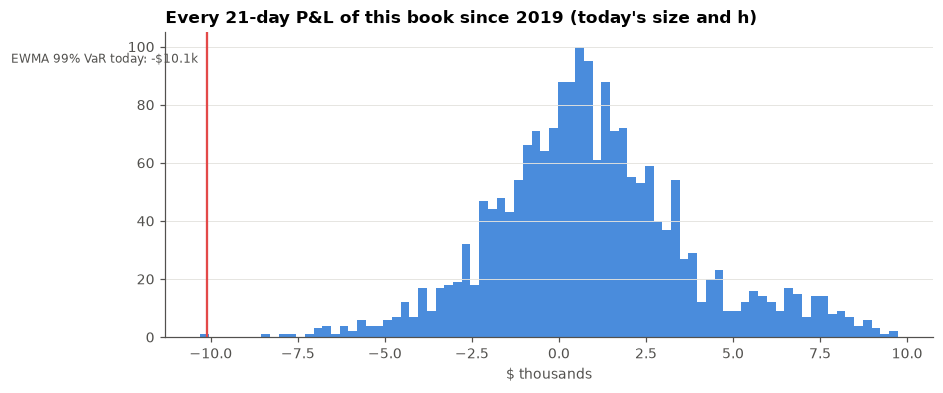

In [4]:
pnl21 = L * u.rolling(M).sum().dropna()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(pnl21 / 1e3, bins=80, color=PALETTE[0], alpha=0.85)
v = sizing["monthly 99% VaR $"] / 1e3
ax.axvline(-v, color=BAD, lw=1.5)
ax.annotate(f"EWMA 99% VaR today: -${v:.1f}k", (-v, ax.get_ylim()[1] * 0.9),
            xytext=(-6, 0), textcoords="offset points", ha="right", color=INK2, fontsize=8)
ax.set_title("Every 21-day P&L of this book since 2019 (today's size and h)")
ax.set_xlabel("$ thousands")
ax.grid(axis="x", visible=False)
save(fig, "03_monthly_var_check")

## 3. Margin and cash, in plain terms

1. You deposit equity.
2. You buy \$32k of NVDA, paying half with your equity and borrowing half from the
   broker (Reg T 50%).
3. You short ~\$41k of QQQ. **The \$41k of proceeds stays at the broker** as
   collateral for the borrowed shares, and you post another 50% of the short on top.
   The proceeds don't pay for anything.

**Reg T equity = 50% x (32k + 41k) ≈ \$36.5k.** Maintenance (25% long, 30% short) is
about \$20k, so a bad month eats into the gap before a margin call. Keep a **\$5-10k
cushion**: fund about \$42-47k. Portfolio margin (~15% per leg ≈ \$11k) would free
capital, but it needs at least \$100k of account equity.

In [5]:
regT = 0.5 * (L + S)
maint = 0.25 * L + 0.30 * S
pm = 0.15 * (L + S)
cash = pd.DataFrame([
    ["deposit equity", regT, 0, 0],
    ["buy NVDA (50% equity, 50% loan)", -0.5 * L, 0, 0.5 * L],
    ["short QQQ: proceeds locked at broker", 0, S, 0],
    ["post 50% extra margin on the short", -0.5 * S, 0.5 * S, 0],
], columns=["step", "your free cash", "locked as short collateral", "margin loan"],
).set_index("step")
cash.loc["end"] = [cash["your free cash"].sum(), cash.iloc[:, 1].sum(), 0.5 * L]
print(f"Reg T equity {usd(regT)}  |  maintenance ~{usd(maint)}  |  "
      f"portfolio margin ~{usd(pm)} (needs $100k+ account)")
cash.style.format("{:,.0f}")

Reg T equity $36,421  |  maintenance ~$20,253  |  portfolio margin ~$10,926 (needs $100k+ account)


,your free cash,locked as short collateral,margin loan
step,,,
deposit equity,"36,421",0,0
"buy NVDA (50% equity, 50% loan)","-16,000",0,"16,000"
short QQQ: proceeds locked at broker,0,"40,843",0
post 50% extra margin on the short,"-20,421","20,421",0
end,0,"61,264","16,000"


**Carry per year at today's rates.** Retail brokers often pay little or nothing on
short proceeds, which changes the sign. Both cases are shown.

In [6]:
rf_now = 252 * rf.iloc[-5:].mean()
fee_now = fee.iloc[-21:].mean()
yfr = pd.read_parquet(load.raw_dir("free") / "yfinance.parquet")
yr = yfr[yfr.date > yfr.date.max() - pd.DateOffset(years=1)]
px = yfr.sort_values("date").groupby("ticker").close.last()
dy = yr.groupby("ticker").dividends.sum() / px
carry = pd.DataFrame({
    "with rebate": {
        "margin loan interest (half of long)": -rf_now * 0.5 * L,
        "interest on short collateral (1.5 x S)": rf_now * 1.5 * S,
        "QQQ borrow fee": -fee_now * S,
        "NVDA dividends received": dy["NVDA"] * L,
        "QQQ dividends paid": -dy["QQQ"] * S},
})
carry["no rebate (retail)"] = carry["with rebate"]
carry.loc["interest on short collateral (1.5 x S)", "no rebate (retail)"] = 0.0
carry.loc["net carry"] = carry.sum()
carry.loc["net carry, % of equity"] = 100 * carry.loc["net carry"] / regT
print(f"T-bill {100 * rf_now:.2f}%, QQQ borrow fee {1e4 * fee_now:.0f} bp")
carry.style.format("{:,.0f}")

T-bill 4.14%, QQQ borrow fee 35 bp


,with rebate,no rebate (retail)
margin loan interest (half of long),-662,-662
interest on short collateral (1.5 x S),"2,534",0
QQQ borrow fee,-144,-144
NVDA dividends received,133,133
QQQ dividends paid,-207,-207
net carry,"1,653",-881
"net carry, % of equity",5,-2


## 4. How it would have done at this size

**Rules:** NVDA long reset to \$32k at each month start. QQQ short reset to `h` x \$32k,
where `h` is refit monthly. Both legs drift within the month. The account pays 10 bp
per side on every dollar traded at a reset (including entry), the Markit borrow fee
daily, and the dividends owed on the short (they're inside QQQ's total return).

**Two choices of `h`:** the **trailing** 252-day beta, and a **shrunk** beta, which is
50% trailing 252-day and 50% the full-sample beta up to that date. Shrinking tames the
swings in the trailing estimate.

Returns are **over T-bills**, as a % of the \$36.5k Reg T equity. "With rebate" earns
T-bill interest on the short collateral. "No rebate" earns nothing on it.

In [7]:
def backtest(h_series, hedged=True):
    """Daily $ P&L over T-bills for the monthly-reset book (helper in nvai.hedge)."""
    h = h_series.dropna() * (1.0 if hedged else 0.0)
    df = hg.monthly_reset_backtest(
        xs_long=xn, g_long=ret.NVDA, xs_short=xq + fee / ANN, g_short=ret.QQQ,
        L_tgt=pd.Series(L, index=h.index), S_tgt=h * L,
        cost_fn=lambda pL, pS, tL, tS, d: TCOST * (abs(tL - pL) + abs(tS - pS)))
    df["pnl_norebate"] = df.pnl - 1.5 * df.short * rf.loc[df.index]
    return df


def stats(p, equity=regT):
    return hg.perf_stats(p, equity)


start = h_shrunk.dropna().index[0]
bt = {"trailing h": backtest(h_trail[start:]), "shrunk h": backtest(h_shrunk[start:]),
      "NVDA unhedged": backtest(h_shrunk[start:], hedged=False)}
perf = pd.DataFrame({
    "shrunk h, rebate": stats(bt["shrunk h"].pnl),
    "shrunk h, no rebate": stats(bt["shrunk h"].pnl_norebate),
    "trailing h, rebate": stats(bt["trailing h"].pnl),
    "trailing h, no rebate": stats(bt["trailing h"].pnl_norebate),
    "NVDA unhedged $32k": stats(bt["NVDA unhedged"].pnl),
})
print(f"backtest {start.date()} to {ret.index[-1].date()}; shrunk h now "
      f"{h_shrunk.iat[-1]:.2f}, trailing h now {h_trail.iat[-1]:.2f}")
perf

backtest 2020-01-02 to 2026-11-20; shrunk h now 1.47, trailing h now 1.27


,"shrunk h, rebate","shrunk h, no rebate","trailing h, rebate","trailing h, no rebate",NVDA unhedged $32k
annual P&L $,"9,432.09","7,004.10","9,417.46","6,885.27","17,412.46"
annual % of equity,25.90,19.23,25.86,18.90,47.81
vol $/yr,"10,508.04","10,507.05","10,519.16","10,518.25","16,727.62"
Sharpe,0.90,0.67,0.90,0.65,1.04
Sortino,1.44,1.06,1.44,1.04,1.57
max drawdown $,"-13,100.79","-19,088.04","-13,638.40","-19,944.32","-29,925.19"
max drawdown % equity,-35.97,-52.41,-37.45,-54.76,-82.16
worst day $,"-3,910.74","-3,926.59","-3,701.21","-3,718.85","-5,772.28"
worst day,2025-01-27,2025-01-27,2025-01-27,2025-01-27,2025-01-27
worst month $,"-6,754.44","-6,921.31","-7,509.55","-7,654.26","-12,440.70"


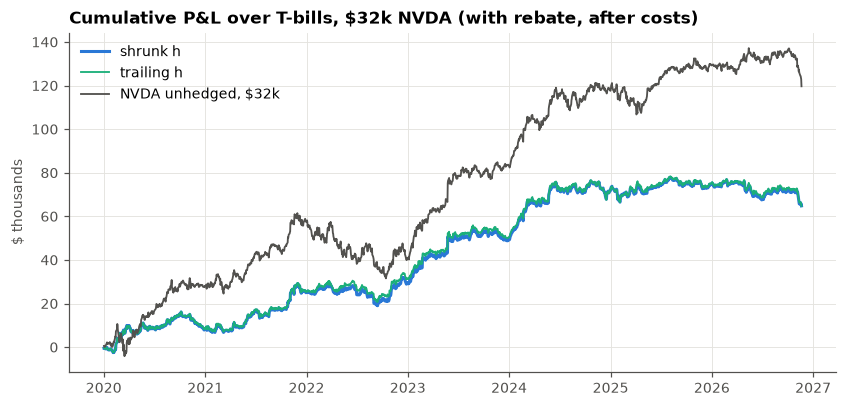

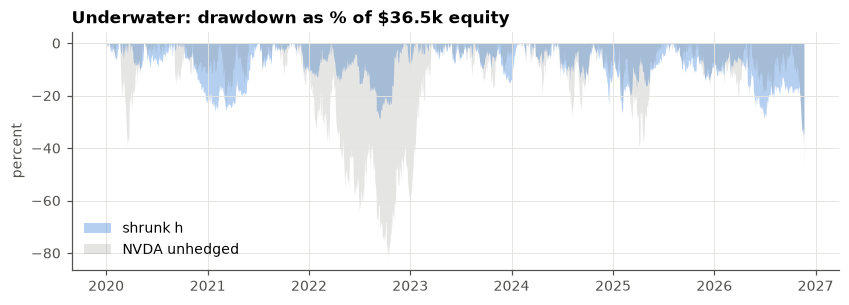

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
for k, c, lw in [("shrunk h", PALETTE[0], 2), ("trailing h", PALETTE[2], 1.2),
                 ("NVDA unhedged", INK2, 1.2)]:
    cum = bt[k].pnl.cumsum()
    ax.plot(cum.index, cum / 1e3, color=c, lw=lw, label=k if k != "NVDA unhedged"
            else "NVDA unhedged, $32k")
ax.set_title("Cumulative P&L over T-bills, $32k NVDA (with rebate, after costs)")
ax.set_ylabel("$ thousands")
ax.legend(loc="upper left")
save(fig, "03_equity_curve")

fig, ax = plt.subplots(figsize=(9, 2.8))
for k, c in [("shrunk h", PALETTE[0]), ("NVDA unhedged", INK2)]:
    cum = bt[k].pnl.cumsum()
    dd = (cum - cum.cummax()) / regT * 100
    ax.fill_between(dd.index, dd, 0, color=c, alpha=0.35 if k == "shrunk h" else 0.15,
                    lw=0, label=k)
ax.set_title("Underwater: drawdown as % of $36.5k equity")
ax.set_ylabel("percent")
ax.legend(loc="lower left")
save(fig, "03_underwater")

## 5. Recent residuals: what the hedge didn't catch

Residual = `xs_NVDA - alpha - h * xs_QQQ`, where `alpha` and `h` come from the trailing
252 days up to the day before. These are NVDA-specific moves. Big ones are labeled,
and earnings dates are marked where yfinance has them.

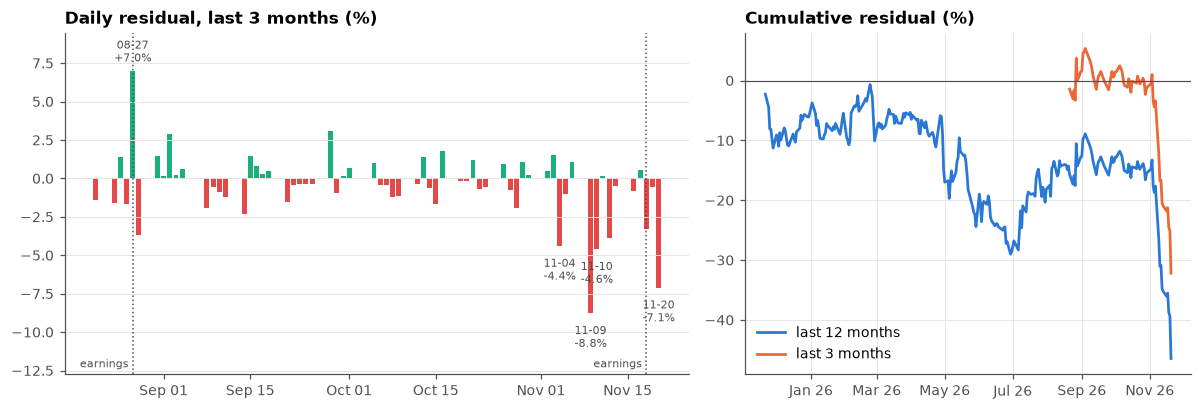

,residual %,earnings reaction day
date,,
2026-08-27,7.00,True
2026-11-04,-4.40,False
2026-11-09,-8.80,False
2026-11-10,-4.60,False
2026-11-20,-7.10,False


In [9]:
mu_n = xn.rolling(252, min_periods=200).mean()
mu_q = xq.rolling(252, min_periods=200).mean()
alpha = (mu_n - b252 * mu_q).shift(1)
resid = (xn - alpha - b252.shift(1) * xq).dropna()
rsd = resid.rolling(252).std().shift(1)

try:
    import yfinance as yf
    ed = yf.Ticker("NVDA").get_earnings_dates(limit=40).index
    earn = pd.DatetimeIndex(ed.tz_localize(None).normalize()).sort_values()
except Exception as e:  # noqa: BLE001 - earnings dates are a nice-to-have
    print("no earnings dates:", type(e).__name__)
    earn = pd.DatetimeIndex([])


def react_day(d):
    """NVDA reports after the close, so the price reaction is the next trading day."""
    later = resid.index[resid.index > d]
    return later[0] if len(later) else None


earn_days = [x for x in (react_day(d) for d in earn) if x is not None]

r3 = resid[resid.index > resid.index[-1] - pd.DateOffset(months=3)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
ax.bar(r3.index, 100 * r3, color=np.where(r3 < 0, BAD, PALETTE[2]), width=0.8)
for d in r3.index[(r3.abs() > 2.5 * rsd.reindex(r3.index))]:
    ax.annotate(f"{d:%m-%d}\n{100 * r3[d]:+.1f}%", (d, 100 * r3[d]),
                xytext=(0, -22 if r3[d] < 0 else 6), textcoords="offset points",
                ha="center", fontsize=7, color=INK2)
lo, hi = 100 * r3.min(), 100 * r3.max()
ax.set_ylim(lo * 1.45, hi * 1.35)
for d in earn_days:
    if d in r3.index:
        ax.axvline(d, color=INK2, ls=":", lw=1)
        ax.annotate("earnings ", (d, lo * 1.4), fontsize=7, color=INK2, ha="right")
ax.set_title("Daily residual, last 3 months (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.grid(axis="x", visible=False)
ax = axes[1]
for months, c in [(12, PALETTE[0]), (3, PALETTE[1])]:
    rr = resid[resid.index > resid.index[-1] - pd.DateOffset(months=months)]
    ax.plot(rr.index, 100 * rr.cumsum(), color=c, lw=1.8, label=f"last {months} months")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_title("Cumulative residual (%)")
ax.legend(loc="lower left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout()
save(fig, "03_recent_residuals")
big = r3[r3.abs() > 2.5 * rsd.reindex(r3.index)].mul(100).round(1).rename("residual %")
pd.DataFrame({"residual %": big, "earnings reaction day": big.index.isin(earn_days)})

## 6. The rolling hedge gap

Two ways the hedge can drift:
- **Spread level:** the running sum of the hedged return, `log NVDA - h x log QQQ`
  (in excess-return terms, with the rolling `h`). It is shown with and without NVDA's
  rolling alpha. If this level wanders far and comes back, there is a mean-reversion
  trade.
- **Beta gap:** the 63-day beta minus the 252-day beta. When it is far from zero, the
  recent relationship differs from the past year, and the monthly-refit hedge is stale.

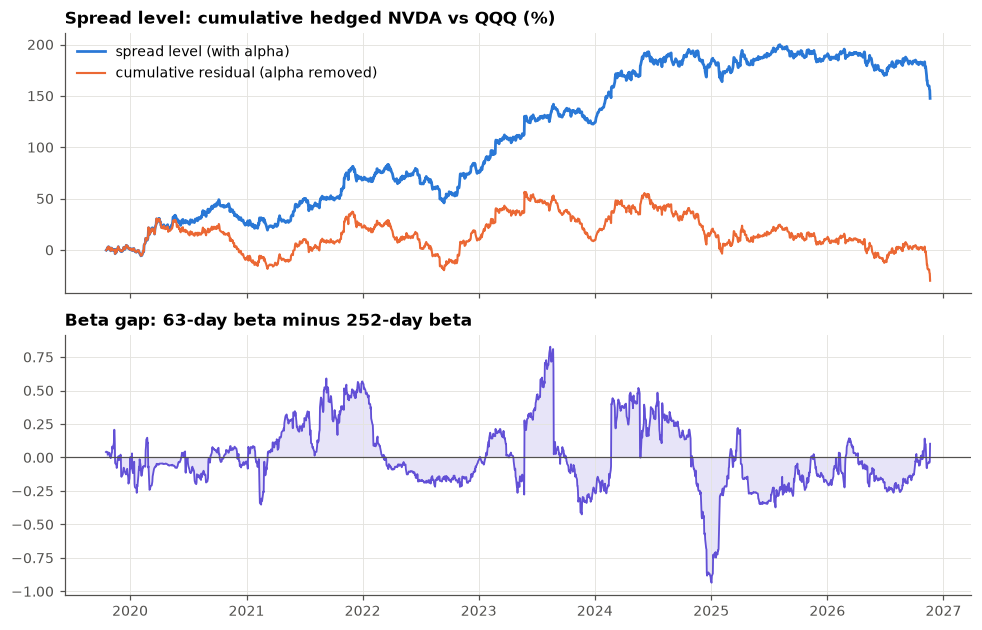

In [10]:
lx = np.log1p(xn) - b252.shift(1) * np.log1p(xq)
spread = lx.dropna().cumsum()                       # includes NVDA's alpha
spread_ex = resid.cumsum()                          # alpha removed
gap = (b63 - b252).dropna()
fig, axes = plt.subplots(2, 1, figsize=(9, 5.8), sharex=True)
axes[0].plot(spread.index, 100 * spread, color=PALETTE[0], lw=1.8,
             label="spread level (with alpha)")
axes[0].plot(spread_ex.index, 100 * spread_ex, color=PALETTE[1], lw=1.4,
             label="cumulative residual (alpha removed)")
axes[0].set_title("Spread level: cumulative hedged NVDA vs QQQ (%)")
axes[0].legend(loc="upper left")
axes[1].plot(gap.index, gap, color=PALETTE[6], lw=1.2)
axes[1].axhline(0, color=INK2, lw=0.8)
axes[1].fill_between(gap.index, gap, 0, color=PALETTE[6], alpha=0.15, lw=0)
axes[1].set_title("Beta gap: 63-day beta minus 252-day beta")
fig.tight_layout()
save(fig, "03_hedge_gap")

## 7. Does it mean-revert?

If the gap snaps back, you could trade it, adding when NVDA has lagged the hedge. If
it is a random walk, there is nothing to time, and the trade is a bet on NVDA's
alpha plus carry. Five checks:
1. **ADF test** on the level. A low p-value means it looks stationary (mean-reverting).
   Run on the full sample and in rolling 252-day windows.
2. **Variance ratio** `VR(q) = var(q-day change) / (q x var(1-day change))`. VR = 1 is
   a random walk and VR < 1 is mean reversion. The z-stat is the
   heteroskedasticity-robust Lo-MacKinlay version.
3. **AR(1) / OU half-life:** `dX = a + b X(-1)`, half-life `= -ln 2 / ln(1 + b)`, with
   a 95% interval from the standard error of `b`.
4. **Event study:** after the 21-day residual falls below -1.5 sigma (or rises above
   +1.5 sigma), what is the average residual over the next 5, 21 and 63 days? Events
   are thinned so a new one needs 21 days since the last.
5. **Autocorrelation** of non-overlapping 21-day residual returns: is a bad month
   followed by a good one?

In [11]:
def adf_p(x):
    return adfuller(x.dropna(), regression="c", autolag="AIC")[1]


def variance_ratio(dx, q):
    dx = dx.dropna().to_numpy()
    mu = dx.mean()
    e = dx - mu
    var1 = (e ** 2).mean()
    xq_ = np.convolve(dx, np.ones(q), "valid") - q * mu
    vr = (xq_ ** 2).mean() / (q * var1)
    # heteroskedasticity-robust asymptotic variance (Lo & MacKinlay 1988)
    theta = sum((2 * (q - j) / q) ** 2 * ((e[j:] ** 2 * e[:-j] ** 2).sum()
                / (e ** 2).sum() ** 2) for j in range(1, q))
    return vr, (vr - 1) / np.sqrt(theta)


def half_life(x):
    x = x.dropna()
    d = sm.OLS(x.diff().iloc[1:], sm.add_constant(x.shift(1).iloc[1:])).fit()
    b, se = d.params.iloc[1], d.bse.iloc[1]

    def hl(bb):
        return -np.log(2) / np.log(1 + bb) if bb < 0 else np.inf
    return b, hl(b), hl(b - 1.96 * se), hl(b + 1.96 * se)


def rolling_adf_share(x, win=252, step=21):
    x = x.dropna()
    ps = [adf_p(x.iloc[i - win:i]) for i in range(win, len(x), step)]
    return np.mean(np.array(ps) < 0.05)


rows = {}
for name, x in [("spread (with alpha)", spread), ("cumulative residual", spread_ex),
                ("beta gap 63d-252d", gap)]:
    b, hl, lo, hi = half_life(x)
    vr5, z5 = variance_ratio(x.diff(), 5)
    vr21, z21 = variance_ratio(x.diff(), 21)
    vr63, z63 = variance_ratio(x.diff(), 63)
    rows[name] = {"ADF p (full)": adf_p(x),
                  "% of 252d windows ADF p<5%": 100 * rolling_adf_share(x),
                  "VR(5)": vr5, "z": z5, "VR(21)": vr21, "z ": z21, "VR(63)": vr63,
                  "z  ": z63, "AR b": b, "half-life (days)": hl,
                  "HL 95% low": lo, "HL 95% high": hi}
MR = pd.DataFrame(rows).T
MR

,ADF p (full),% of 252d windows ADF p<5%,VR(5),z,VR(21),z,VR(63),z,AR b,half-life (days),HL 95% low,HL 95% high
spread (with alpha),0.48,8.22,0.93,-1.11,0.89,-0.82,0.86,-0.62,-0.00,631.37,283.59,inf
cumulative residual,0.46,5.48,0.93,-1.17,0.93,-0.54,0.97,-0.13,-0.01,136.24,65.44,inf
beta gap 63d-252d,0.00,15.07,1.05,0.67,1.00,0.02,0.93,-0.29,-0.02,45.25,29.43,96.95


Reading the table: under a random walk, about 5% of rolling windows reject the ADF
test by chance alone. A half-life of `inf` means the AR coefficient is not negative.

In [12]:
r21 = resid.rolling(M).sum()
z = r21 / (resid.rolling(252).std() * np.sqrt(M))
fwd = {k: resid[::-1].rolling(k).sum()[::-1].shift(-1) for k in (5, 21, 63)}


def events(mask):
    picks, last = [], None
    for d in mask[mask].index:
        if last is None or (resid.index.get_loc(d) - resid.index.get_loc(last)) >= M:
            picks.append(d)
            last = d
    return pd.DatetimeIndex(picks)


ev_rows = []
for side, mask in [("after 21d residual < -1.5 sigma", z < -1.5),
                   ("after 21d residual > +1.5 sigma", z > 1.5)]:
    ev = events(mask.fillna(False))
    for k, f in fwd.items():
        x = f.reindex(ev).dropna()
        ev_rows.append({"signal": side, "horizon (days)": k, "events": len(x),
                        "avg fwd residual %": 100 * x.mean(),
                        "t-stat": x.mean() / (x.std() / np.sqrt(len(x))),
                        "share positive %": 100 * (x > 0).mean()})
EV = pd.DataFrame(ev_rows).set_index(["signal", "horizon (days)"])
mon = resid.groupby(resid.index.to_period("M")).sum()
ac1 = mon.autocorr(1)
print(f"autocorrelation of monthly residuals: {ac1:+.2f} "
      f"(t ~ {ac1 * np.sqrt(len(mon)):+.1f}, {len(mon)} months)")
EV

autocorrelation of monthly residuals: +0.11 (t ~ +1.0, 86 months)


events  avg fwd residual %  t-stat  share positive %
signal                          horizon (days)                                                      
after 21d residual < -1.5 sigma 5                   14               -0.30   -0.30             42.86
                                21                  13               -0.89   -0.54             46.15
                                63                  13                0.12    0.03             30.77
after 21d residual > +1.5 sigma 5                   12               -0.89   -0.52             41.67
                                21                  12                1.52    0.44             58.33
                                63                  12                4.19    1.03             58.33

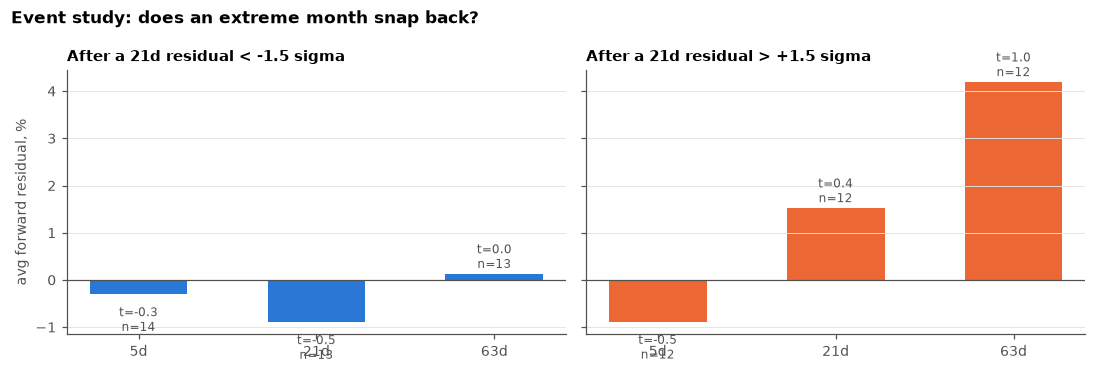

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, side, c in [(axes[0], "after 21d residual < -1.5 sigma", PALETTE[0]),
                    (axes[1], "after 21d residual > +1.5 sigma", PALETTE[1])]:
    t = EV.loc[side]
    ax.bar([str(k) + "d" for k in t.index], t["avg fwd residual %"], color=c, width=0.55)
    for i, (k, r) in enumerate(t.iterrows()):
        ax.annotate(f"t={r['t-stat']:.1f}\nn={r['events']:.0f}",
                    (i, r["avg fwd residual %"]), xytext=(0, 4 if r["avg fwd residual %"]
                    >= 0 else -24), textcoords="offset points", ha="center", fontsize=8,
                    color=INK2)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_title(side.replace("after ", "After a "), fontsize=10)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("avg forward residual, %")
fig.suptitle("Event study: does an extreme month snap back?", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
save(fig, "03_event_study")

## 8. Bottom line

Hedging with QQQ turns NVDA into a cleaner bet on NVDA's own story. It cuts dollar vol
by about 40% and the worst drawdown by more than half, at the cost of giving up the
market-driven part of the upside. That story drove the profits from 2020 to 2025, and
it is what has gone wrong in the last three months. There is no statistical evidence that the
hedged spread snaps back after a bad stretch, so a drawdown is not by itself a reason to add.
Size for a \$10k monthly VaR, keep a \$5-10k margin cushion, check the rebate your
broker pays (it swings carry from +\$1.7k to -\$0.9k a year), and refit `h` monthly
with some shrinkage toward the long-run beta.